# D2_01 상관분석

> **오늘 질문:** 어떤 센서끼리 함께 움직이고, 고장과 관련 있는 센서는 무엇일까?

| 표시 | 의미 |
|---|---|
| 📋 제공 | 코드가 들어 있습니다. 실행만 하세요 |
| ✍️ 입력 | 설명을 보고 직접 입력하세요 |
| 💬 해석 | 결과를 보고 답을 적어 보세요 |

## 0. 준비 📋

In [1]:
%matplotlib inline
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats

df = pd.read_parquet("../../data/factory_table.parquet")
sensors = ["air_temp", "process_temp", "rpm", "torque", "tool_wear", "vibration", "failure"]

## 1. 피어슨 상관계수 ✍️

`corr()`는 기본으로 피어슨(직선 관계) 상관계수를 계산합니다.

> 변수 이름: `corr`

In [2]:
# 힌트: df[컬럼목록].corr()
corr = df[sensors].corr()
corr.round(2)

,air_temp,process_temp,rpm,torque,tool_wear,vibration,failure
air_temp,1.00,0.88,0.02,-0.01,0.01,0.02,0.08
process_temp,0.88,1.00,0.02,-0.01,0.01,0.01,0.04
rpm,0.02,0.02,1.00,-0.88,0.00,-0.01,-0.04
torque,-0.01,-0.01,-0.88,1.00,-0.00,0.04,0.19
tool_wear,0.01,0.01,0.00,-0.00,1.00,0.02,0.11
vibration,0.02,0.01,-0.01,0.04,0.02,1.00,0.21
failure,0.08,0.04,-0.04,0.19,0.11,0.21,1.00


## 2. 히트맵으로 보기 ✍️

`vmin=-1, vmax=1`로 색 범위를 고정해야 색만 보고도 강약을 비교할 수 있습니다.

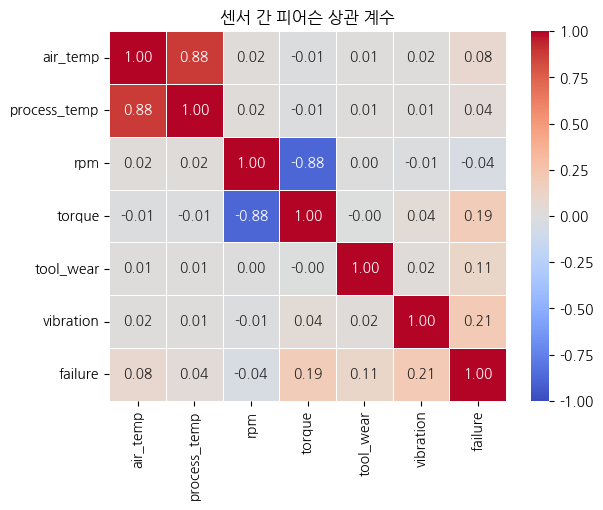

In [8]:
# 힌트: sns.heatmap(표, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title("센서 간 피어슨 상관 계수")
plt.show()

**Q1.** 공기 온도와 공정 온도의 상관이 매우 높습니다(0.88). 공기 온도가 공정 온도의 원인일까요?

> 답:


## 3. 피어슨 vs 스피어만 ✍️

회전수와 토크는 곡선 관계입니다(1일차 산점도). 스피어만은 순위로 계산해서 곡선이라도 한 방향이면 강하게 나옵니다.

In [10]:
# 힌트: 컬럼1.corr(컬럼2, method="spearman")
print(f"피어슨: {df['rpm'].corr(df['torque']):.2f}")
print(f"스피어만: {df['rpm'].corr(df['torque'], method='spearman'):.2f}")

피어슨: -0.88
스피어만: -0.92


## 4. 상관도 검정할 수 있다 ✍️

`stats.pearsonr()`은 상관계수와 함께 p-value를 줍니다. p-value는 "상관이 0이라고 가정했을 때 이런 결과가 나올 확률"입니다.

In [12]:
# 힌트: stats.pearsonr(컬럼1, 컬럼2)
result = stats.pearsonr(df['tool_wear'], df['failure'])
print(f"상관계수 {result.statistic:.3f}, p-value {result.pvalue:.2e}")

상관계수 0.105, p-value 3.98e-26


**Q2.** 공구 마모와 고장의 상관계수는 약 0.11로 약하지만 p-value는 아주 작습니다. 어떻게 해석해야 할까요?

> 답:


## 정리 💬

**Q3.** 히트맵에서 `failure`와 상관이 가장 큰 센서 두 개는? 그 센서만 보면 고장을 예측할 수 있을까요?

> 답:
